# Information, Invariance and Generalisation

<i> by Hardik Rajpal </i>

This notebook explores the fundamental concepts of Information Theory and how they extend to the Information Bottle framework in Deep Learning to enable robust generalisation.

## 1. What is information?

Information is defined as the 'surprise' of an event. For a given event with probability $p_i$, the information is:
$$I(p_i) = -\log(p_i)$$

**Shannon entropy** is the average information across all possible outcomes:
$$H = -\sum_{i} p_i \log(p_i)$$

### Exercise: Complete the Entropy Function
Fill in the core calculation for Shannon Entropy in the function below.

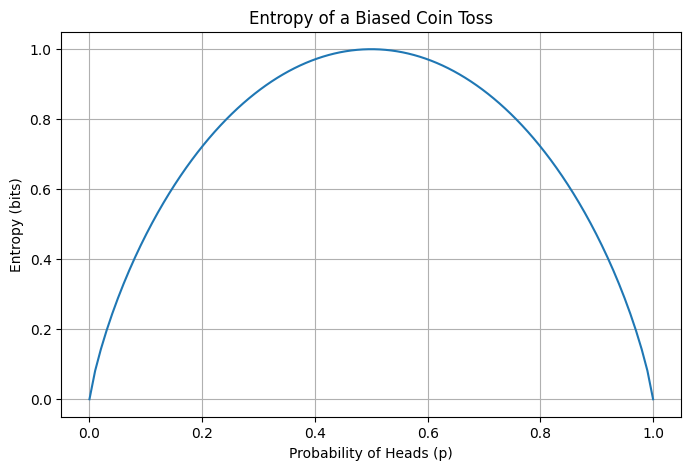

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def calculate_entropy(probabilities):
    """
    Takes a list of probabilities and returns the Shannon entropy.
    """
    assert np.isclose(np.sum(probabilities), 1), "Probabilities must sum to 1."
    probabilities = np.array(probabilities)
    # Filter out zero probabilities to avoid log(0)
    p = probabilities[probabilities > 0]

    # TODO: Complete the formula for entropy H
    entropy = -np.dot(p, np.log2(p))

    return entropy

# Biased coin toss example
p_heads = np.linspace(0, 1, 100)
entropies = [calculate_entropy([p, 1-p]) for p in p_heads]

plt.figure(figsize=(8, 5))
plt.plot(p_heads, entropies)
plt.title('Entropy of a Biased Coin Toss')
plt.xlabel('Probability of Heads (p)')
plt.ylabel('Entropy (bits)')
plt.grid(True)
plt.show()

## 2. Mutual Information

Mutual Information (MI) measures how much information is shared between two variables. Unlike Pearson correlation, which only detects linear relationships, MI can capture non-linear interdependencies.

### Linear vs. Non-linear mappings
We will compare how MI and Pearson correlation behave when we introduce a dependency between two binary sequences $x$ and $y$ controlled by a probability $p$.

### 2.1 Implementing Mutual Information

The Mutual Information between two discrete variables $X$ and $Y$ is defined as:
$$I(X;Y) = \sum_{x \in \mathcal{X}} \sum_{y \in \mathcal{Y}} p(x,y) \log\left( \frac{p(x,y)}{p(x)p(y)} \right)$$

Where:
* $p(x,y)$ is the joint probability distribution of $X$ and $Y$.
* $p(x)$ and $p(y)$ are the marginal probability distributions of $X$ and $Y$ respectively.

In [5]:
def calculate_mutual_information(x, y):
    """
    Calculates mutual information between two binary sequences x and y.
    """
    n = len(x)

    #1. Compute marginal probabilities p(x)
    values_x, counts_x = np.unique(x, return_counts=True)
    p_x = counts_x / n

    #2. Compute marginal probabilities p(y)
    values_y, counts_y = np.unique(y, return_counts=True)
    p_y = counts_y / n


    # 2. Compute joint probability p(x, y) using np.unique
    # We stack x and y to find unique pairs (rows)
    combined = np.vstack((x, y)).T
    unique_pairs, counts = np.unique(combined, axis=0, return_counts=True)
    p_xy_dict = {tuple(pair): count/n for pair, count in zip(unique_pairs, counts)}

    mi = 0.0
    for val_x in values_x:
        for val_y in values_y:
            p_joint = p_xy_dict.get((val_x, val_y), 0.0)
            p_marg_x = p_x[val_x]
            p_marg_y = p_y[val_y]

            if p_joint > 0:
                # TODO: Complete the MI calculation using the formula
                mi += -p_joint * np.log2((p_marg_x*p_marg_y)/p_joint)

    return mi

### 2.2 Comparing Mappings

We will now compare two types of dependencies:
1. **Linear Mapping**: $y$ simply copies binary $x$ with probability $p$.
2. **Non-linear (Quadratic)**: Here $x$ can take three values (-1, 0, 1). $y$ is defined as the $y = x^2$.

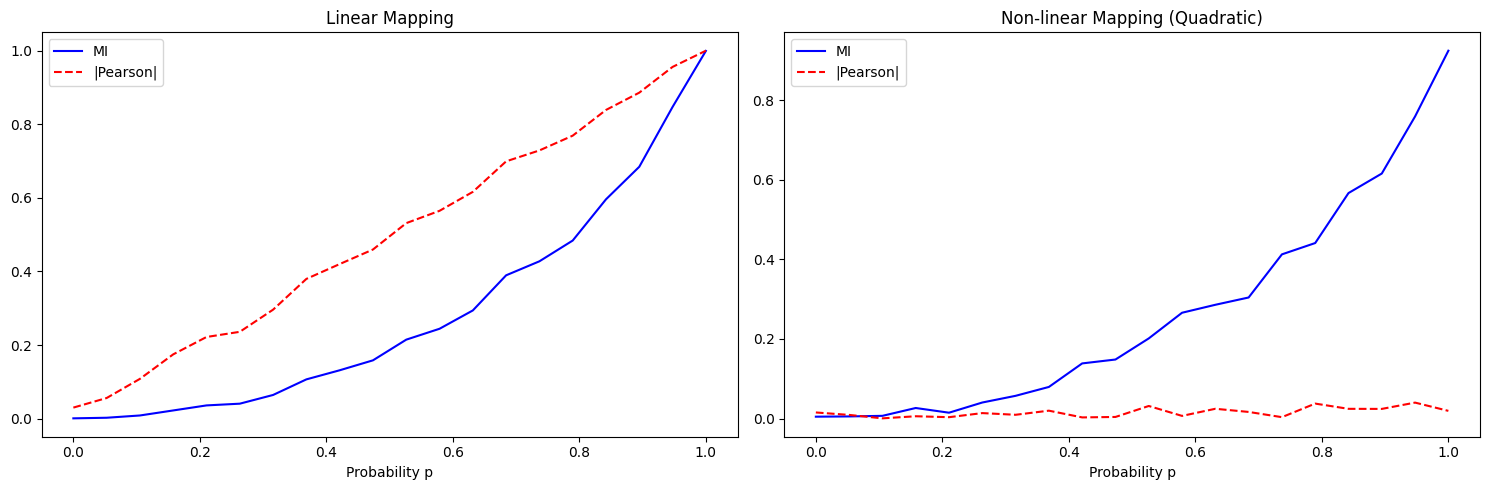

In [6]:
from scipy.stats import pearsonr

def get_linear_y(x, p):
    # y ~ x with probability p, otherwise it is random
    mask = np.random.rand(len(x)) < p
    y = np.random.randint(0, 2, len(x))  # Start with random y
    y[mask] = x[mask]
    return y

def get_quadratic_y(x, p):
    # y ~ x^2 with probability p, otherwise it is random
    n = len(x)
    y = np.array([int(x[i]**2) if np.random.rand() < p else np.random.randint(0, 2) for i in range(n)])
    return y

ps = np.linspace(0, 1, 20)
results = {'linear': {'mi': [], 'corr': []}, 'quadratic': {'mi': [], 'corr': []}}

n_samples = 2000
x = np.random.randint(0, 2, n_samples)

for p in ps:
    # Linear
    x = np.random.randint(0, 2, n_samples) # x is binary in [0, 1]
    y_lin = get_linear_y(x, p)
    results['linear']['mi'].append(calculate_mutual_information(x, y_lin))
    results['linear']['corr'].append(abs(pearsonr(x, y_lin)[0]))

    # Non-linear (Quadratic)
    x = np.random.randint(0, 3, n_samples) - 1 # x takes values [-1, 0, 1]
    y_par = get_quadratic_y(x, p)
    results['quadratic']['mi'].append(calculate_mutual_information(x, y_par))
    results['quadratic']['corr'].append(abs(pearsonr(x, y_par)[0]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(ps, results['linear']['mi'], 'b-', label='MI')
ax1.plot(ps, results['linear']['corr'], 'r--', label='|Pearson|')
ax1.set_title('Linear Mapping')
ax1.set_xlabel('Probability p')
ax1.legend()

ax2.plot(ps, results['quadratic']['mi'], 'b-', label='MI')
ax2.plot(ps, results['quadratic']['corr'], 'r--', label='|Pearson|')
ax2.set_title('Non-linear Mapping (Quadratic)')
ax2.set_xlabel('Probability p')
ax2.legend()

plt.tight_layout()
plt.show()

### 2.3 Continuous Mutual Information: Gaussian Case

When dealing with continuous variables, calculating MI can be more complex. However, if two variables $X$ and $Y$ follow a joint Multivariate Gaussian distribution, the Mutual Information can be calculated analytically using their covariance matrix $\Sigma$.

The formula for Gaussian Mutual Information is:
$$I(X; Y) = \frac{1}{2} \ln \left( \frac{|\Sigma_{XX}| |\Sigma_{YY}|}{|\Sigma|} \right)$$

Where:
* $|\Sigma|$ is the determinant of the joint covariance matrix.
* $|\Sigma_{XX}|$ and $|\Sigma_{YY}|$ are the determinants of the marginal covariance matrices.

In [7]:
def calculate_gaussian_mi(X, Y):
    """
    Calculates Gaussian Mutual Information between X and Y.
    X and Y can be multi-dimensional arrays.
    """
    # Stack X and Y to create the joint distribution
    joint = np.vstack([X, Y])

    # Compute the covariance matrices
    cov_joint = np.cov(joint)
    cov_X = np.cov(X)
    cov_Y = np.cov(Y)

    # Handle 1D case for determinants (ensure they are 2D for np.linalg.det)
    det_joint = np.linalg.det(np.atleast_2d(cov_joint))
    det_X = np.linalg.det(np.atleast_2d(cov_X))
    det_Y = np.linalg.det(np.atleast_2d(cov_Y))

    # TODO: Complete the formula for Gaussian MI
    # mi = ...

    return mi

In [ ]:
rhos = np.linspace(0, 0.99, 50)
gaussian_mi_results = []

n_samples = 5000

for rho in rhos:
    # Generate a 2D Gaussian with correlation rho
    mean = [0, 0]
    cov = [[1, rho], [rho, 1]]
    data = np.random.multivariate_normal(mean, cov, n_samples).T

    X, Y = data[0:1, :], data[1:2, :]
    mi = calculate_gaussian_mi(X, Y)
    gaussian_mi_results.append(mi)

plt.figure(figsize=(8, 5))
plt.plot(rhos, gaussian_mi_results, lw=2)
plt.title('Gaussian Mutual Information vs. Correlation Coefficient (rho)')
plt.xlabel('Correlation Coefficient (rho)')
plt.ylabel('Mutual Information (nats)')
plt.grid(True, alpha=0.3)
plt.show()

## 3. Information Bottleneck

The Information Bottleneck (IB) principle provides a framework for understanding how deep learning models extract useful features. Given an input $X$, a target output $Y$, and a learned representation (or latent code) $Z$, we want to find a representation $Z$ that is as concise as possible while still being highly predictive of $Y$.

This is formulated as an optimization problem where we minimize the IB objective function:
$$\mathcal{L} = \beta I(X; Z) -  I(Y; Z)$$

Where:
* **$I(X; Z)$**: The information the representation $Z$ retains about the input $X$. Minimizing this encourages compression and the removal of irrelevant noise.
* **$I(Y; Z)$**: The information the representation $Z$ contains about the target $Y$. Maximizing this ensures the representation is useful for the task.
* **$\beta$**: A trade-off parameter (Lagrange multiplier) that controls the balance between compression and task accuracy.

By constraining $Z$ to be low-dimensional (a "bottleneck"), we force the model to capture the **invariant features**—the underlying patterns that are necessary for generalisation while ignoring superficial fluctuations in the input data.

## Exercise: Nuisance Signals and Invariance

In this exercise we investigate how the IB penalty helps a model ignore 'nuisance' signals — input features that are correlated with the target during training but uninformative at test time.

### The Data Setup

We define a 3D input $X = [a, b, c]$ and a scalar target $Y = a + b$:

<table width="100%">
  <thead>
    <tr>
      <th>Variable</th>
      <th>Distribution</th>
      <th>Role</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>$a \sim \mathcal{N}(0,1)$</td>
      <td>signal component 1</td>
      <td>contributes to $Y$</td>
    </tr>
    <tr>
      <td>$b \sim \mathcal{N}(0,1)$</td>
      <td>signal component 2</td>
      <td>contributes to $Y$</td>
    </tr>
    <tr>
      <td>$c_\text{train} = (a+b) + \mathcal{N}(0, 0.05)$</td>
      <td>near-perfect proxy for $Y$ during training</td>
      <td>gradient descent will greedily use $c$</td>
    </tr>
    <tr>
      <td>$c_\text{test} \sim \mathcal{N}(0,1)$</td>
      <td>independent noise at test time</td>
      <td>any reliance on $c$ gives high test MSE</td>
    </tr>
  </tbody>
</table>

This train/test distribution shift on $c$ is the setup that makes IB useful. Without the IB penalty the model exploits the shortcut $c \approx Y$. The IB penalty forces it to compress $Z$ until only the true signal $(a, b)$ survives.

### Model Architecture (3 → 2 → 1)

Both models share the same architecture — a linear encoder projecting the 3D input to a 2D bottleneck $Z$, followed by a linear decoder:

$$Z = W_\text{enc} \cdot [a, b, c]^\top \qquad \hat{Y} = w_\text{dec} \cdot Z$$

The 2D bottleneck is narrower than the 3D input, forcing the encoder to compress. The key question is *which* input dimensions survive.

### Comparison: MSE vs. IB Training

**Case 1 — MSE Only**: trained end-to-end to minimise $\text{MSE}(Y, \hat{Y})$. Gradient descent exploits $c$ because it nearly perfectly predicts $Y$ during training, which fails at test time.

**Case 2 — Information Bottleneck (two-phase training)**:

- **Phase 1** trains only the encoder with the IB objective $\beta \cdot I(X;Z) - I(Y;Z)$. The $-I(Y;Z)$ term pushes the encoder toward dimensions informative about $Y$; $+\beta \cdot I(X;Z)$ penalises encoding the full input, discouraging reliance on the nuisance $c$.
- **Phase 2** freezes the encoder and trains only the decoder with MSE — a linear readout on top of the fixed representation.

By sweeping $\beta$ we trace the IB trade-off: small $\beta$ still uses the shortcut; optimal $\beta$ suppresses the nuisance $(\|w_c\| \to 0)$ and minimises test MSE; large $\beta$ over-compresses and degrades performance.


### 3.1 Case 1: MSE Only Loss

In this baseline case, we train the model to minimize the standard Mean Squared Error. We will monitor the latent representation $Z$ to see if the model naturally ignores the nuisance signal $c$.

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim

class ClassicMLP(nn.Module):
    """
    Linear MLP model: 3 input features, 2 hidden units, 1 output unit.
    """
    def __init__(self):
        super(ClassicMLP, self).__init__()
        self.hidden = nn.Linear(3, 2, bias=False)
        self.output = nn.Linear(2, 1, bias=False)

    def forward(self, x):
        z = self.hidden(x)
        y_hat = self.output(z)
        return y_hat, z


In [9]:
def generate_nuisance_data(n_samples=1000, mode='train'):
    """
    Generates a linear-Gaussian dataset designed so that the IB trade-off is sharp and visible.

    Input X = [a, b, c] (3D):
      a ~ N(0, 1)
      b ~ N(0, 1)
      c = a + b + N(0, 0.05)   (train)  — a near-perfect proxy for Y; gradient descent will
                                       prefer to use c since it has higher SNR per weight unit
      c ~ N(0, 1)          (test)   — pure independent noise; a model relying on c gets
                                       test MSE ≈ Var(Y) + Var(c) ≈ 2

    Target Y = a + b  (1D)
    """
    np.random.seed(42)
    a = np.random.normal(0, 1, n_samples)
    b = np.random.normal(0, 1, n_samples)
    s = a + b

    if mode == 'train':
        c = s + np.random.normal(0, 0.05, n_samples)
    else:
        c = np.random.normal(0, 1, n_samples)

    X = np.stack([a, b, c], axis=1)
    y = s.reshape(-1, 1)
    return (torch.tensor(X, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32))

X_train, y_train = generate_nuisance_data(10000, mode='train')
X_test,  y_test  = generate_nuisance_data(1000, mode='test')

print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Train: torch.Size([10000, 3]), Test: torch.Size([1000, 3])


ClassicMLP(
  (hidden): Linear(in_features=3, out_features=2, bias=False)
  (output): Linear(in_features=2, out_features=1, bias=False)
)
Hidden weights: tensor([[ 0.5647,  0.5698,  0.4079],
        [-0.4792, -0.1857,  0.2011]])
Output weights: tensor([[-0.3748,  0.1529]])
Epoch [200/200], Loss: 0.0006  |  w_s=0.6842  w_c=0.6475


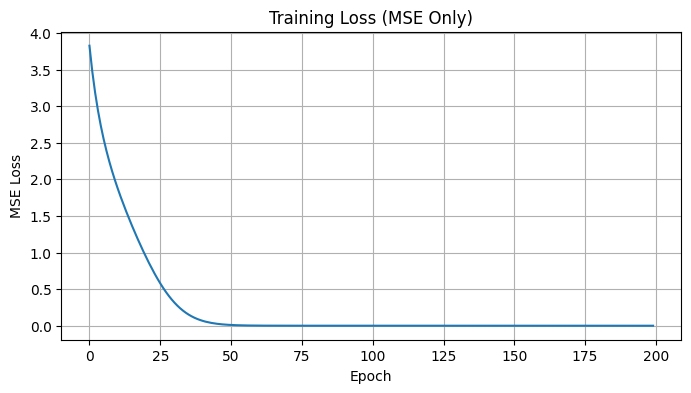


Final encoder weights:  w_ab = 0.9420,   w_c = 0.6021


In [10]:
model_mse = ClassicMLP()
criterion = nn.MSELoss()
optimizer = optim.SGD(model_mse.parameters(), lr=0.01)

print(model_mse)
print(f"Hidden weights: {model_mse.hidden.weight.data}")
print(f"Output weights: {model_mse.output.weight.data}")

# Training loop for MSE Only model
epochs = 200
losses = []

model_mse.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    y_hat, z = model_mse(X_train)
    loss = criterion(y_hat, y_train)
    losses.append(loss.item())
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 200 == 0:
        w = model_mse.hidden.weight.data[0]
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}  |  w_s={w[0]:.4f}  w_c={w[1]:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.title('Training Loss (MSE Only)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.show()

w = model_mse.hidden.weight.data[0]
print(f"\nFinal encoder weights:  w_ab = {torch.norm(w[:2]):.4f},   w_c = {torch.norm(w[2]):.4f}")


Test MSE Loss: 0.7340


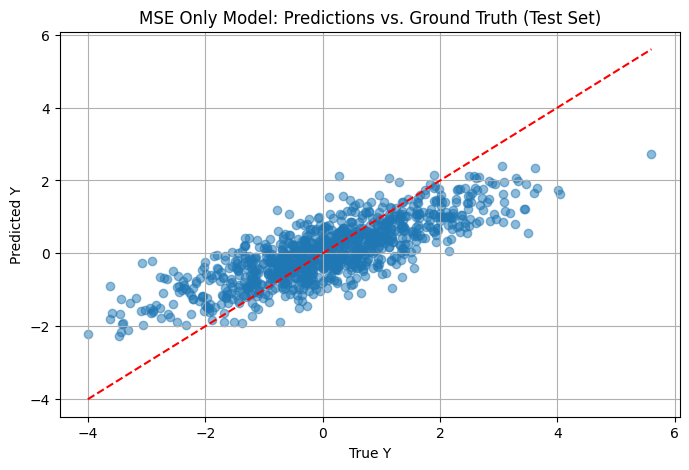

In [11]:
model_mse.eval()
with torch.no_grad():
    y_test_hat, _ = model_mse(X_test)
    test_loss = criterion(y_test_hat, y_test)

print(f'Test MSE Loss: {test_loss.item():.4f}')

# Visualize Predictions vs True Values
plt.figure(figsize=(8, 5))
plt.scatter(y_test.numpy(), y_test_hat.numpy(), alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title('MSE Only Model: Predictions vs. Ground Truth (Test Set)')
plt.xlabel('True Y')
plt.ylabel('Predicted Y')
plt.grid(True)
plt.show()

### 4.2 Case 2: Information Bottleneck (IB) Loss

We train this model in **two separate phases**, keeping the encoder and decoder objectives clean and non-conflicting.

**Phase 1 — Learn the representation** (100 epochs, encoder only):

$$\mathcal{L}_\text{enc} = \beta \cdot I(X; Z) - I(Y; Z)$$

- $-I(Y;Z)$: maximise the information the bottleneck retains about the **target** $Y$. This term is **direction-sensitive** — its gradient depends on how well $Z$ predicts $Y$, so it pushes the encoder toward the true signal $s$
- $+\beta \cdot I(X;Z)$: compression penalty — penalise retaining *any* information about the full input $X$, discouraging the encoder from encoding the nuisance $c$

Only the encoder weights are updated in this phase. The decoder is untouched.

**Phase 2 — Fit the decoder** (100 epochs, decoder only, encoder frozen):

$$\mathcal{L}_\text{dec} = \text{MSE}(Y, \hat{Y})$$

The encoder weights are frozen. A linear decoder is trained by simple regression on top of the fixed representation $Z$. This cleanly separates *what is encoded* from *how it is decoded*.

To calculate $I(X;Z)$ and $I(Y;Z)$ during Phase 1, we use the differentiable Gaussian MI estimator from Section 2.3.

In [12]:
def torch_gaussian_mi(x, z):
    """
    Differentiable Gaussian Mutual Information estimator using PyTorch.
    Uses log-determinant directly for numerical stability (avoids det() underflow).
    I(X;Z) = 0.5 * [logdet(Cov_X) + logdet(Cov_Z) - logdet(Cov_XZ)]
    """
    joint = torch.cat((x, z), dim=1)

    def get_log_det_cov(data):
        n = data.size(0)
        data_centered = data - data.mean(dim=0)
        cov = (data_centered.t() @ data_centered) / (n - 1)
        # Regularise for numerical stability
        cov = cov + torch.eye(cov.size(0), dtype=data.dtype) * 1e-5
        return torch.logdet(cov)

    log_det_joint = get_log_det_cov(joint)
    log_det_x     = get_log_det_cov(x)
    log_det_z     = get_log_det_cov(z)

    mi = 0.5 * (log_det_x + log_det_z - log_det_joint)
    return mi


In [15]:
def ib_loss_function(y, x, z, beta=0.01):
    """
    IB Loss = beta * I(X; Z) - I(Y; Z)
    z is the bottleneck representation learned by the network.
    X is the input data and Y is the output.
    """
    mi_xz = torch_gaussian_mi(x, z)
    mi_yz = torch_gaussian_mi(y, z)
    # TODO: maximize I(Y;Z) while minimizing I(X;Z)
    total_loss = beta * mi_xz - mi_yz
    return total_loss, mi_xz, mi_yz

class IBMLP(nn.Module):
    """
    IB MLP model: 3 input features, 2 hidden units, 1 output unit.
    We train the encoder using the IB loss function, which includes the Gaussian MI estimator.
    We separately train the decoder using MSE only to ensure it can learn the optimal linear mapping from the bottleneck representation to Y.
    """
    def __init__(self):
        super(IBMLP, self).__init__()
        self.hidden = nn.Linear(3, 2, bias=False)
        self.output = nn.Linear(2, 1, bias=False)

    def forward(self, x):
        z = self.hidden(x)
        y_hat = self.output(z)
        return y_hat, z




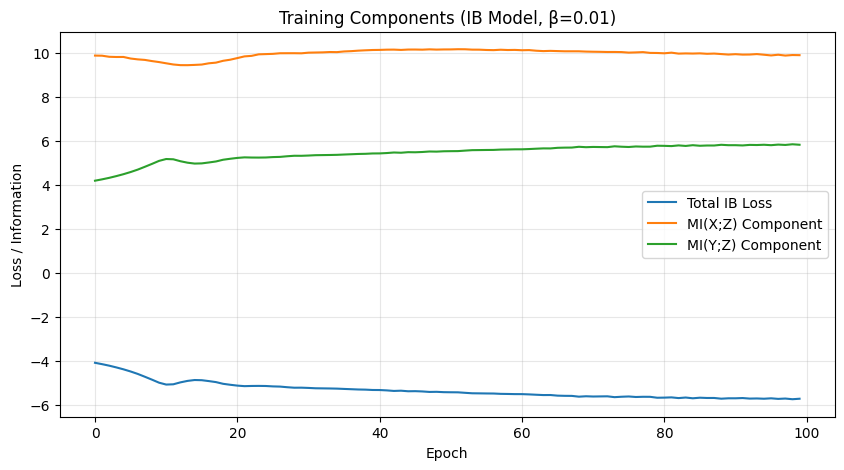

In [16]:

beta = 0.01
model_ib = IBMLP()
# Optimizer for the encoder (hidden layer) using the IB loss
optimizer_ib = optim.Adam(model_ib.hidden.parameters(), lr=0.01)

epochs = 100
ib_total_losses = []
ib_mi_input = []
ib_mi_output = []

model_ib.hidden.train()
for epoch in range(epochs):
    optimizer_ib.zero_grad()
    y_hat, z = model_ib(X_train)
    loss, mi_xz, mi_yz = ib_loss_function(y_train, X_train, z, beta=beta)

    ib_total_losses.append(loss.item())
    ib_mi_input.append(mi_xz.item())
    ib_mi_output.append(mi_yz.item())

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model_ib.hidden.parameters(), max_norm=1.0)
    optimizer_ib.step()

    if (epoch + 1) % 200 == 0:
        w = model_ib.hidden.weight.data[0]
        print(f'Epoch [{epoch+1}/{epochs}]  Total: {loss.item():.4f}  Input MI: {mi_xz.item():.4f}  '
              f'Output MI: {mi_yz.item():.4f}  |  w_s={w[0]:.4f}  w_c={w[1]:.4f}')

plt.figure(figsize=(10, 5))
plt.plot(ib_total_losses, label='Total IB Loss')
plt.plot(ib_mi_input, label='MI(X;Z) Component')
plt.plot(ib_mi_output, label='MI(Y;Z) Component')
plt.title(f'Training Components (IB Model, β={beta})')
plt.xlabel('Epoch')
plt.ylabel('Loss / Information')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Final decoder MSE Loss after separate training: 0.0063


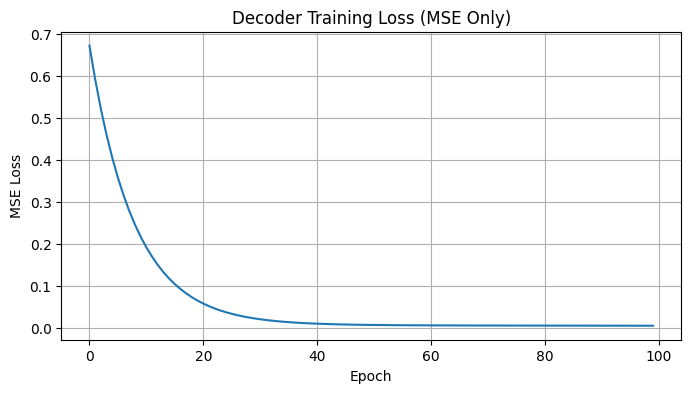

In [17]:
# Training the decoder separately with MSE only

optimizer_decoder = optim.SGD(model_ib.output.parameters(), lr=0.01)
decoder_epochs = 100
decoder_losses = []
model_ib.output.train()  # Set decoder to training mode
for epoch in range(decoder_epochs):
    optimizer_decoder.zero_grad()
    y_hat, _ = model_ib(X_train)  # Forward pass through the whole model
    loss = criterion(y_hat, y_train)  # MSE loss on the output
    decoder_losses.append(loss.item())
    loss.backward()  # Backpropagate only through the decoder parameters
    optimizer_decoder.step()

print(f"Final decoder MSE Loss after separate training: {decoder_losses[-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(decoder_losses)
plt.title('Decoder Training Loss (MSE Only)')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.show()

IB Model Test MSE Loss: 0.0185


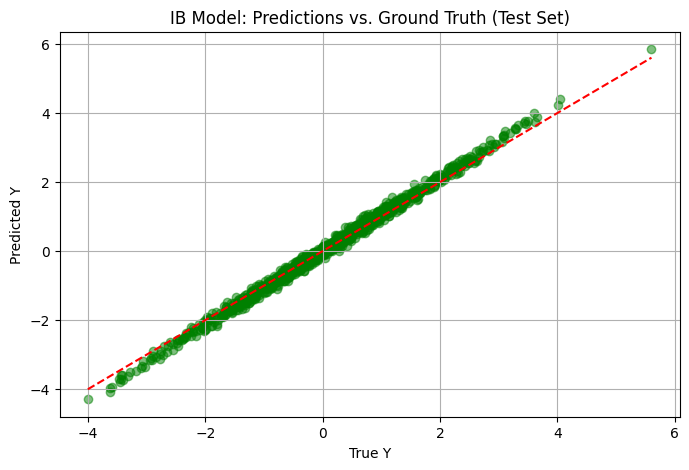

In [18]:
model_ib.eval()
with torch.no_grad():
    y_test_hat_ib, _ = model_ib(X_test)
    test_loss_ib = nn.MSELoss()(y_test_hat_ib, y_test)

print(f'IB Model Test MSE Loss: {test_loss_ib.item():.4f}')

# Visualize Predictions vs True Values
plt.figure(figsize=(8, 5))
plt.scatter(y_test.numpy(), y_test_hat_ib.numpy(), alpha=0.5, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title('IB Model: Predictions vs. Ground Truth (Test Set)')
plt.xlabel('True Y')
plt.ylabel('Predicted Y')
plt.grid(True)
plt.show()

### 4.3 Hyperparameter Optimisation for $\beta$
The noise penalty parameter $\beta$ needs to be tuned such that we are not killikng the signal along with the noise.

In [20]:
def run_ib_experiment(beta_val, phase1_epochs=200, phase2_epochs=200, seed=42):
    torch.manual_seed(seed)
    criterion = nn.MSELoss()

    model = IBMLP()

    # ── Phase 1: Train encoder only with IB loss ─────────────────────────────
    opt_enc = optim.Adam(model.hidden.parameters(), lr=0.01)
    model.hidden.train()

    for epoch in range(phase1_epochs):
        opt_enc.zero_grad()
        y_hat, z = model(X_train)
        loss, mi_xz, mi_yz = ib_loss_function(y_train, X_train, z, beta=beta_val)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.hidden.parameters(), max_norm=1.0)
        opt_enc.step()

    # ── Phase 2: Freeze encoder, train decoder with MSE ──────────────────────
    for p in model.hidden.parameters():
        p.requires_grad = False

    opt_dec = optim.SGD(model.output.parameters(), lr=0.01)
    model.output.train()

    for epoch in range(phase2_epochs):
        opt_dec.zero_grad()
        with torch.no_grad():
            z = model.hidden(X_train)
        y_hat = model.output(z)
        loss = criterion(y_hat, y_train)
        loss.backward()
        opt_dec.step()

    # ── Evaluation ────────────────────────────────────────────────────────────
    model.eval()
    with torch.no_grad():
        y_train_hat, z_train = model(X_train)
        train_mse = criterion(y_train_hat, y_train).item()
        final_mi  = torch_gaussian_mi(X_train, z_train).item()
        y_test_hat, _ = model(X_test)
        test_mse = criterion(y_test_hat, y_test).item()

    # w_s: norm of hidden weights on signal inputs [a, b] (columns 0 and 1)
    # w_c: norm of hidden weights on nuisance input [c]  (column 2)
    W = model.hidden.weight.data          # shape (2, 3)
    w_s = W[:, :2].norm().item()
    w_c = W[:,  2].norm().item()
    return train_mse, final_mi, test_mse, w_s, w_c


  Beta   Train MSE    Test MSE    I(X;Z)     ‖w_s‖     ‖w_c‖
--------------------------------------------------------------
 0.000      0.0151      0.0219    10.343    2.7533    0.1226
 0.000      0.0149      0.0215    10.289    2.7529    0.1207
 0.000      0.0141      0.0204    10.310    2.7497    0.1207
 0.000      0.0143      0.0208    10.228    2.7471    0.1203
 0.001      0.0147      0.0216    10.249    2.7470    0.1209
 0.001      0.0151      0.0229    10.239    2.7532    0.1237
 0.002      0.0149      0.0232    10.198    2.7464    0.1239
 0.003      0.0138      0.0223    10.118    2.7399    0.1226
 0.005      0.0117      0.0211     9.963    2.7314    0.1219
 0.008      0.0062      0.0222     9.448    2.7163    0.1297
 0.013      0.0006      0.0109     8.078    2.5783    0.1145
 0.021      0.0000      0.0077     6.286    2.3163    0.0921
 0.034      0.0000      0.0060     6.170    2.0441    0.0812
 0.055      0.0000      0.0040     6.553    1.7906    0.0642
 0.089      0.0000    

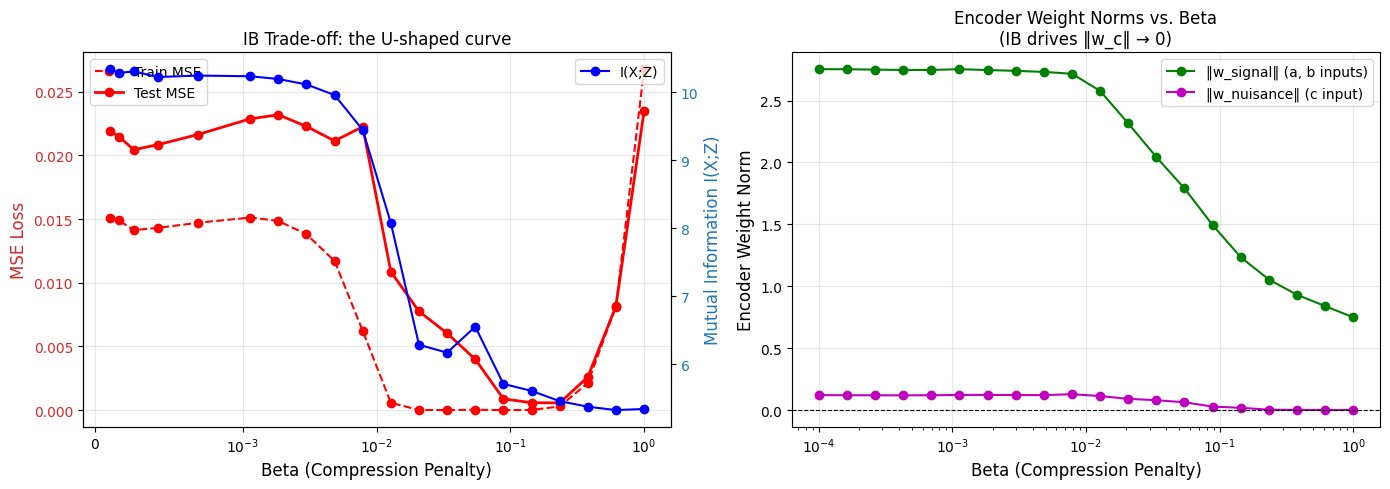

In [21]:
beta_range = 10**np.linspace(-4, 0, 20)  # from 0.001 to 1 on a log scale
results = {'train_mse': [], 'mi': [], 'test_mse': [], 'w_s': [], 'w_c': []}

print(f"{'Beta':>6}  {'Train MSE':>10}  {'Test MSE':>10}  {'I(X;Z)':>8}  {'‖w_s‖':>8}  {'‖w_c‖':>8}")
print("-" * 62)
for b in beta_range:
    t_mse, mi, v_mse, w_s, w_c = run_ib_experiment(b)
    results['train_mse'].append(t_mse)
    results['mi'].append(mi)
    results['test_mse'].append(v_mse)
    results['w_s'].append(w_s)
    results['w_c'].append(w_c)
    print(f"{b:>6.3f}  {t_mse:>10.4f}  {v_mse:>10.4f}  {mi:>8.3f}  {w_s:>8.4f}  {w_c:>8.4f}")

# ── Plot ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
ax1.set_xlabel('Beta (Compression Penalty)', fontsize=12)
ax1.set_ylabel('MSE Loss', color='tab:red', fontsize=12)
ax1.plot(beta_range, results['train_mse'], 'r--o', label='Train MSE')
ax1.plot(beta_range, results['test_mse'],  'r-o',  label='Test MSE', lw=2)
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.set_xscale('symlog', linthresh=0.001)

ax1b = ax1.twinx()
ax1b.set_ylabel('Mutual Information I(X;Z)', color='tab:blue', fontsize=12)
ax1b.plot(beta_range, results['mi'], 'b-o', label='I(X;Z)')
ax1b.tick_params(axis='y', labelcolor='tab:blue')

ax1.set_title('IB Trade-off: the U-shaped curve')
ax1.legend(loc='upper left')
ax1b.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

ax2 = axes[1]
ax2.plot(beta_range, results['w_s'], 'g-o', label='‖w_signal‖ (a, b inputs)')
ax2.plot(beta_range, results['w_c'], 'm-o', label='‖w_nuisance‖ (c input)')
ax2.axhline(0, color='k', lw=0.8, ls='--')
ax2.set_xlabel('Beta (Compression Penalty)', fontsize=12)
ax2.set_ylabel('Encoder Weight Norm', fontsize=12)
ax2.set_title('Encoder Weight Norms vs. Beta\n(IB drives ‖w_c‖ → 0)')
ax2.set_xscale('log')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
